# 26 · Diagnóstico comercial

Fonte: [Desafios](../docs/02-desafios-sql.md#d26)

Analise a evolução das contratações e identifique períodos de crescimento ou queda. Crie um gráfico temporal e descreva três observações sustentadas pelos dados.

In [2]:
from dashboards.database import engine
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import MaxNLocator

In [3]:
df = pd.read_csv("reports/analise_avancada/20_evolucao_contratacoes_mensal.csv")

df["data"] = pd.to_datetime({
    'year': df["ano"],
    'month': df["mes"],
    'day': 1
})

df = df[["data", "quantidade_contratos"]]

df = df.sort_values("data").reset_index(drop=True)
df.head(100)




,data,quantidade_contratos
0,2023-11-01,52
1,2023-12-01,36
2,2024-01-01,40
3,2024-02-01,41
4,2024-03-01,38
5,2024-04-01,46
6,2024-05-01,42
7,2024-06-01,51
8,2024-07-01,58
9,2024-08-01,41


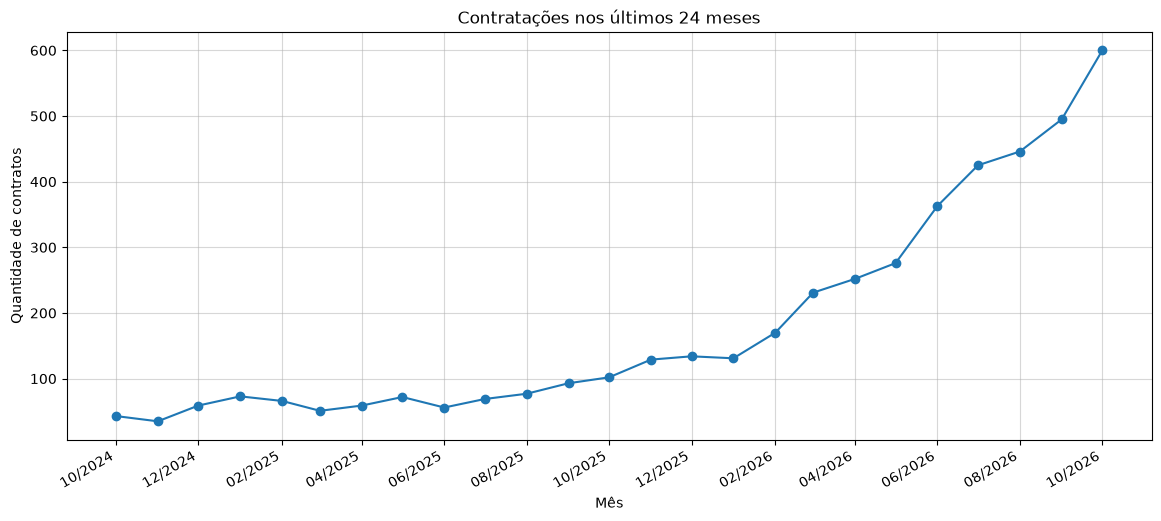

In [4]:
data_final = df["data"].max()
data_inicial = data_final - pd.DateOffset(months=24)

df_recente = df.loc[
    df["data"] >= data_inicial
]

fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    df_recente["data"],
    df_recente["quantidade_contratos"],
    marker="o"
)

ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))

ax.set(
    title="Contratações nos últimos 24 meses",
    xlabel="Mês",
    ylabel="Quantidade de contratos"
)

ax.grid(alpha=0.5)
fig.autofmt_xdate()
plt.show()

,data_cadastro,quantidade_clientes
0,2023-10,3
1,2023-11,18
2,2023-12,31
3,2024-01,35
4,2024-02,37
5,2024-03,48
6,2024-04,36
7,2024-05,25
8,2024-06,42
9,2024-07,38


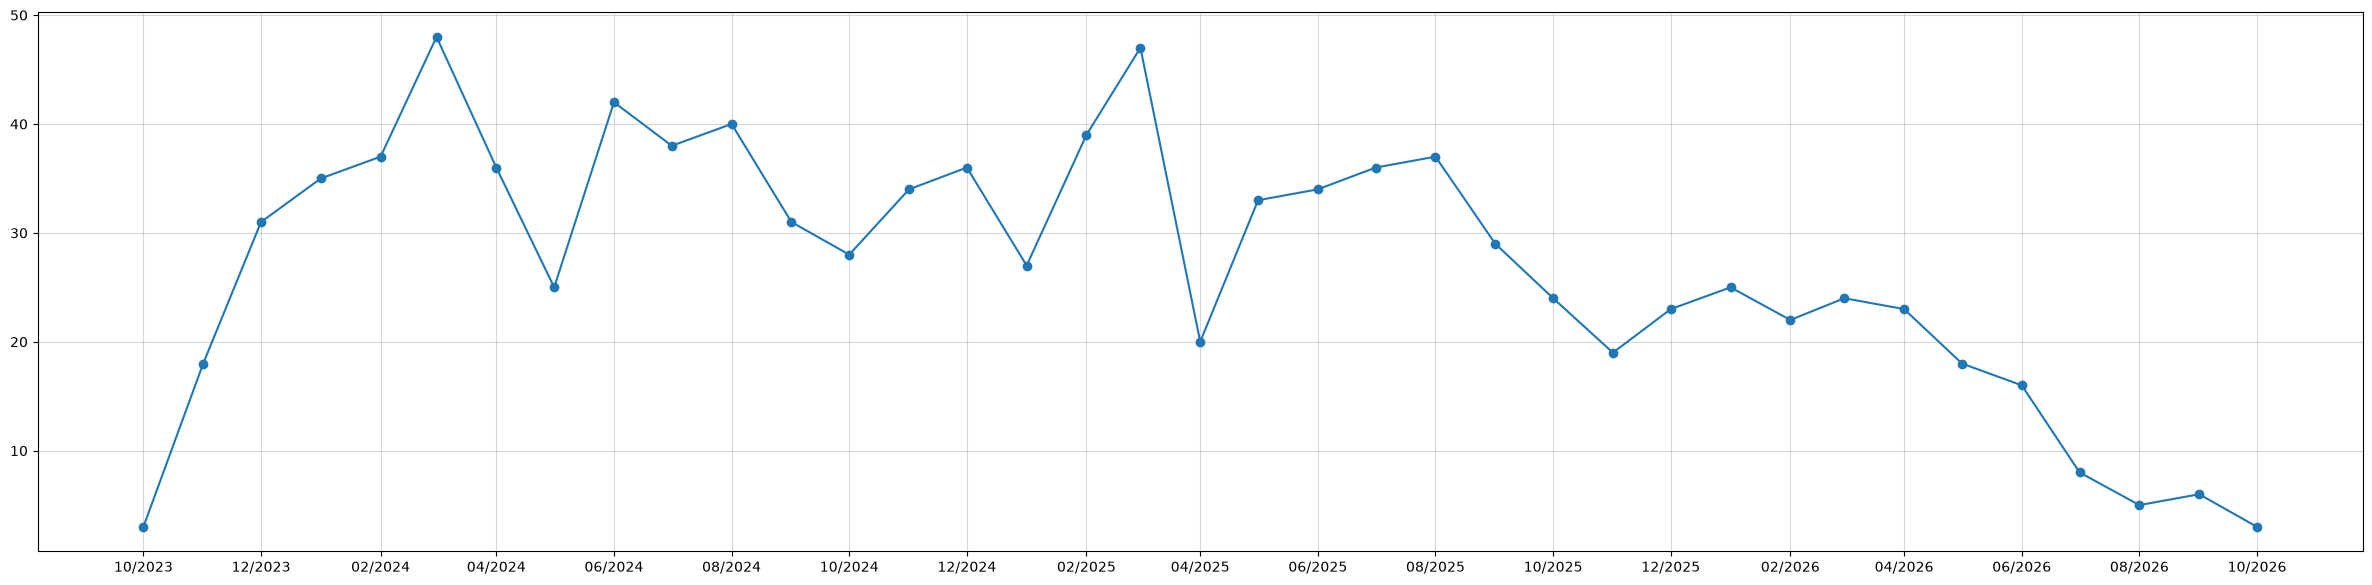

In [14]:
#pelo gráfico, o número de contratções aumentou exponencialmente a partir de 2026, agora vale investigar,se esse aumento é,
# devido a mais clientes se cadastrando, e contratando mais serviços, ou clientes ja cadastrados contratando mais serviços

clientes = pd.read_sql_table(
    "clientes",
    con=engine,
    schema="nexus",
    columns=["id","data_cadastro"]
)

x = clientes["data_cadastro"].dt.to_period("M")
clientes["data_cadastro"] = x
display(clientes.groupby("data_cadastro").count().reset_index().sort_values("data_cadastro").rename(columns={"id":"quantidade_clientes"}))
fig, ax = plt.subplots(figsize=(30, 7))
ax.plot(
    clientes.groupby("data_cadastro").count().reset_index().sort_values("data_cadastro").rename(columns={"id":"quantidade_clientes"})["data_cadastro"].dt.to_timestamp(),
    clientes.groupby("data_cadastro").count().reset_index().sort_values("data_cadastro").rename(columns={"id":"quantidade_clientes"})["quantidade_clientes"],
    marker="o"
)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))

plt.grid(alpha=0.5)
plt.show()